# 06 · Final model evaluation

Reads every model's forecasts from `mart.fact_forecast` (the same numbers the dashboards use) and compares them on hourly accuracy, daily-peak accuracy and error by hour, season and temperature band. Run notebooks 02, 03 and 04 first.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.db import get_engine
from src.features import load_features, add_groups, assign_split
from src.evaluate import summarize, error_by

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "docs" / "results"; RES.mkdir(parents=True, exist_ok=True)

feats = assign_split(add_groups(load_features()))
q = """SELECT f.ts, m.model_name, f.split, f.forecast_mw, f.actual_mw, l.is_imputed
       FROM mart.fact_forecast f
       JOIN mart.dim_model m USING (model_key)
       JOIN mart.fact_load_hourly l USING (ts)
       WHERE f.split IN ('validation', 'test')"""
fc = pd.read_sql(q, get_engine(), parse_dates=["ts"])
fc = fc.rename(columns={"actual_mw": "load_mw"})
groups = feats[["ts", "hour_of_day", "season", "temp_band", "day_type"]]
print(fc.groupby(["model_name", "split"]).size().unstack())

split            test  validation
model_name                       
lightgbm        13897        8784
prophet         13897        8784
seasonal_naive  13897        8784


## Accuracy table

In [3]:
tables = [summarize(g.assign(forecast_mw=g["forecast_mw"]), "forecast_mw", name) for name, g in fc.groupby("model_name")]
tables.append(summarize(feats, "load_lag_24h", "same_hour_yesterday (benchmark)"))
allm = pd.concat(tables, ignore_index=True)
allm.to_csv(RES / "model_comparison.csv", index=False)
test = allm[allm["split"] == "test"].set_index("model")
cols = ["WAPE_%", "MAPE_%", "RMSE_MW", "peak_MAE_MW", "peak_hour_within_1h_%"]
test[cols].sort_values("WAPE_%").round(2)

,WAPE_%,MAPE_%,RMSE_MW,peak_MAE_MW,peak_hour_within_1h_%
model,,,,,
lightgbm,3.19,3.16,1294.05,1126.09,76.12
prophet,6.05,6.19,2376.11,2049.99,56.57
same_hour_yesterday (benchmark),7.40,7.32,3134.38,2618.00,66.09
seasonal_naive,11.30,10.99,4794.30,4388.97,64.53


In [4]:
ref = "seasonal_naive"
if "lightgbm" in test.index:
    w = test["WAPE_%"]
    print(f"LightGBM test WAPE {w['lightgbm']:.2f}%")
    print(f"  vs seasonal naive ({w[ref]:.2f}%):        {(1 - w['lightgbm'] / w[ref]) * 100:+.1f}%")
    y = w["same_hour_yesterday (benchmark)"]
    print(f"  vs same hour yesterday ({y:.2f}%): {(1 - w['lightgbm'] / y) * 100:+.1f}%")
    p = test["peak_MAE_MW"]
    print(f"daily peak error: lightgbm {p['lightgbm']:,.0f} MW vs naive {p[ref]:,.0f} MW")

LightGBM test WAPE 3.19%
  vs seasonal naive (11.30%):        +71.8%
  vs same hour yesterday (7.40%): +56.9%
daily peak error: lightgbm 1,126 MW vs naive 4,389 MW


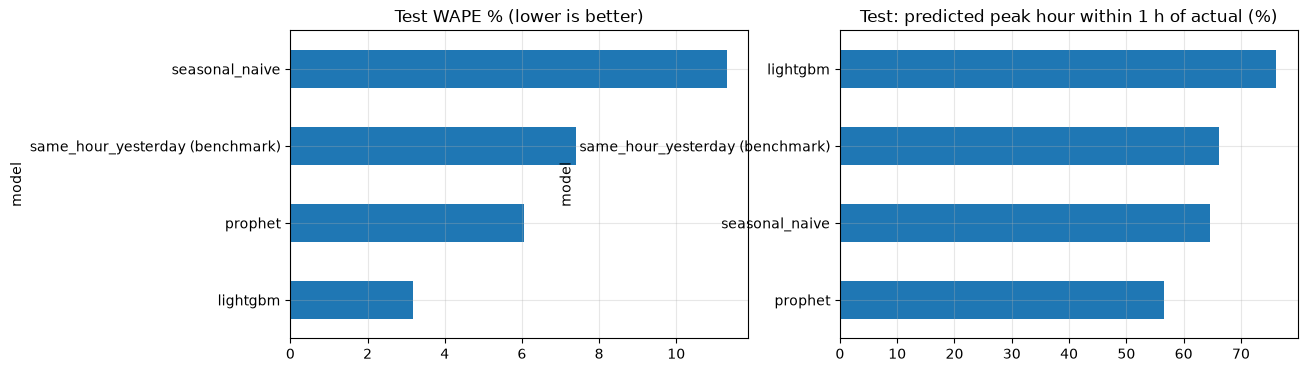

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test["WAPE_%"].sort_values().plot.barh(ax=axes[0], title="Test WAPE % (lower is better)")
test["peak_hour_within_1h_%"].sort_values().plot.barh(ax=axes[1], title="Test: predicted peak hour within 1 h of actual (%)")
fig.savefig(FIG / "model_comparison.png", dpi=150, bbox_inches="tight")

## Error by hour, season and temperature band (test period)

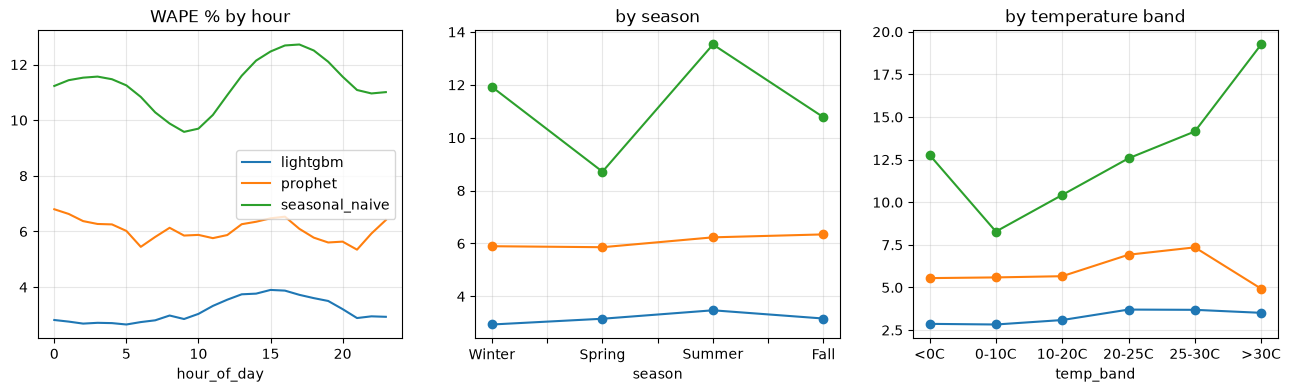

In [6]:
t = fc[fc["split"] == "test"].merge(groups, on="ts")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, g in t.groupby("model_name"):
    error_by(g, "hour_of_day", "forecast_mw")["WAPE_%"].plot(ax=axes[0], label=name)
    error_by(g, "season", "forecast_mw")["WAPE_%"].reindex(["Winter", "Spring", "Summer", "Fall"]).plot(ax=axes[1], label=name, marker="o")
    error_by(g, "temp_band", "forecast_mw")["WAPE_%"].plot(ax=axes[2], label=name, marker="o")
axes[0].set_title("WAPE % by hour"); axes[1].set_title("by season"); axes[2].set_title("by temperature band")
axes[0].legend()
fig.savefig(FIG / "model_error_breakdown.png", dpi=150, bbox_inches="tight")